# Baseline: log-normal fit of the time between blinks

Fits a log-normal distribution to the intervals between blinks in the first 10 minutes of the
earliest recording that lasts at least 10 minutes. Blink detection and intervals come from the
app's own code (`ocusense.core.replay`), so they match **Statistics › All time** exactly.
Recordings are only read, never changed.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ocusense").is_dir())
sys.path.insert(0, str(ROOT))

from ocusense.recording import default_directory
from ocusense.recording_files import RecordingError, group, read_file
from ocusense.core.replay import replay

BASELINE_SECONDS = 600.0
MIN_INTERVALS = 30
FOLDER = default_directory()  # ~/Library/Application Support/OcuSense/recordings

## a. Pick the baseline recording

Read every CSV with `read_file`, leave out calibration-only files (`calibration: null`) and
join the rest with `group()`, the same rules as `analysis/check_recordings.py`. Then take the
earliest joined recording that lasts at least 10 minutes and keep the rows from its first
600 s (`replay()` has no `until` argument, so the rows are cut before replaying).

In [2]:
files = []
for path in sorted(FOLDER.glob("ear_*.csv")):
    try:
        f = read_file(path)
    except RecordingError as error:
        print("excluded:", error)
        continue
    if f.calibration is not None:
        files.append(f)

recording = next(r for r in group(files) if r.seconds >= BASELINE_SECONDS)
rows = recording.rows
start = rows[0].t
baseline_rows = [row for row in rows if row.t - start < BASELINE_SECONDS]

print("Recording:", recording.label())
print("Calibration:", recording.calibration.label())
print(f"Rows used: {len(baseline_rows)} of {len(rows)}, "
      f"{baseline_rows[-1].t - start:.1f} s from the first row")

Recording: Sat 10 Oct 2026, 18:11:32 · 60 min 1 s · 7 files
Calibration: calibrated 2026-10-10 18:11:32 · closes below 35%, reopens above 65% · ear-personal-v2
Rows used: 17990 of 107870, 600.0 s from the first row


## b. Intervals between blinks (app code)

`replay()` runs the rows through the app's calibration, detector and measurements.
`interval_seconds()` gives onset-to-onset times between consecutive completed blinks inside the
same valid segment, never across a gap (see docs/measurements.md §11.2).

In [3]:
result = replay(baseline_rows, recording.calibration)
d = result.distributions
intervals = np.array(d.interval_seconds())

print(f"Valid frames: {result.valid_frames} of {result.frames} "
      f"({result.valid_frames / result.frames:.0%}), valid time {d.valid_seconds:.0f} s")
print(f"Blinks counted: {d.blinks}, valid segments: {d.segments}, intervals: {len(intervals)}")

Valid frames: 11288 of 17990 (63%), valid time 374 s
Blinks counted: 97, valid segments: 83, intervals: 62


## c. Log-normal fit

If the intervals are log-normal, their natural logs are normal. **mu** is the mean of the logs
and **sigma** is their standard deviation, using the **sample std (ddof = 1)**. The maximum-
likelihood value (ddof = 0) is printed too for comparison. Median = exp(mu),
mean = exp(mu + sigma²/2).

In [4]:
logs = np.log(intervals)
n = len(logs)
mu = logs.mean()
sigma = logs.std(ddof=1)

print(f"n      = {n}")
print(f"mu     = {mu:.4f}   (log seconds)")
print(f"sigma  = {sigma:.4f}   (ddof=1; ddof=0 would give {logs.std(ddof=0):.4f})")
print(f"median = exp(mu)             = {np.exp(mu):.2f} s   (observed median {np.median(intervals):.2f} s)")
print(f"mean   = exp(mu + sigma²/2)  = {np.exp(mu + sigma**2 / 2):.2f} s   (observed mean {intervals.mean():.2f} s)")

n      = 62
mu     = 0.7122   (log seconds)
sigma  = 0.9251   (ddof=1; ddof=0 would give 0.9176)
median = exp(mu)             = 2.04 s   (observed median 1.79 s)
mean   = exp(mu + sigma²/2)  = 3.13 s   (observed mean 3.21 s)


## d. Is the fit good?

Three pictures: the intervals with the fitted log-normal density, the logs with the fitted
normal density, and a Q–Q plot of the logs (points on the line = normal logs). Then a
Kolmogorov–Smirnov test on the logs. Its p-value is **optimistic** (too high) because mu and
sigma were estimated from the same data. A Lilliefors correction would be stricter.

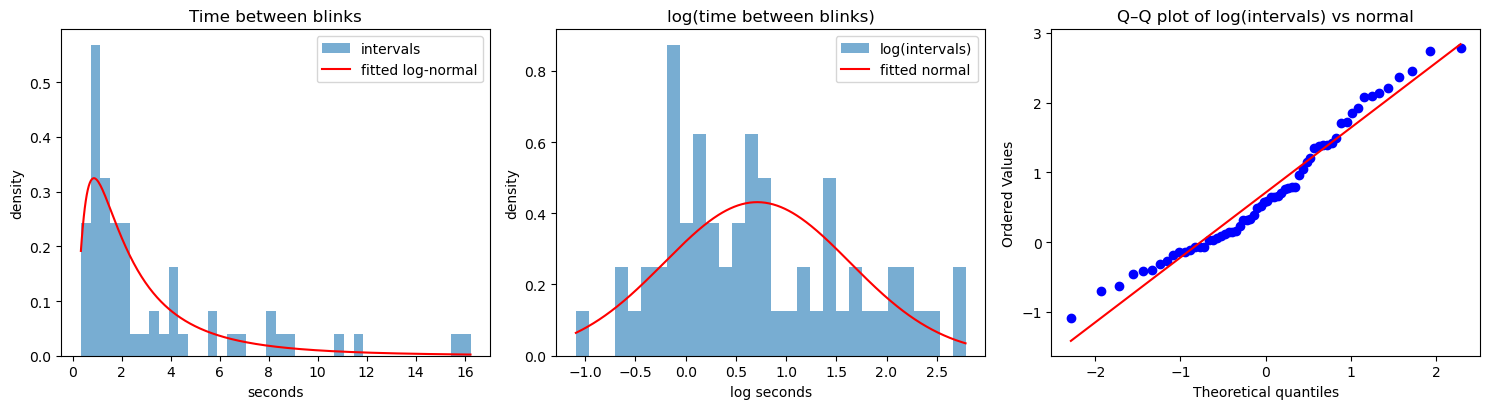

KS statistic D = 0.1123, p = 0.386  (optimistic: mu, sigma estimated from these data)


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
ax.hist(intervals, bins=40, density=True, alpha=0.6, label="intervals")
x = np.linspace(intervals.min(), intervals.max(), 400)
ax.plot(x, stats.lognorm.pdf(x, s=sigma, scale=np.exp(mu)), "r", label="fitted log-normal")
ax.set(title="Time between blinks", xlabel="seconds", ylabel="density")
ax.legend()

ax = axes[1]
ax.hist(logs, bins=30, density=True, alpha=0.6, label="log(intervals)")
x = np.linspace(logs.min(), logs.max(), 400)
ax.plot(x, stats.norm.pdf(x, mu, sigma), "r", label="fitted normal")
ax.set(title="log(time between blinks)", xlabel="log seconds", ylabel="density")
ax.legend()

stats.probplot(logs, dist="norm", plot=axes[2])
axes[2].set(title="Q–Q plot of log(intervals) vs normal")

plt.tight_layout()
plt.show()

ks = stats.kstest(logs, stats.norm(mu, sigma).cdf)
print(f"KS statistic D = {ks.statistic:.4f}, p = {ks.pvalue:.3f}  (optimistic: mu, sigma estimated from these data)")

## e. Summary

In [6]:
print(f"Baseline: first {BASELINE_SECONDS / 60:.0f} min of {recording.started:%Y-%m-%d %H:%M:%S}")
print(f"n = {n} intervals, mu = {mu:.3f}, sigma = {sigma:.3f} (ddof=1)")
print(f"Median {np.exp(mu):.2f} s, mean {np.exp(mu + sigma**2 / 2):.2f} s between blink onsets")
print(f"KS on logs: D = {ks.statistic:.3f}, p = {ks.pvalue:.3f} (optimistic)")
if n < MIN_INTERVALS:
    print(f"WARNING: only {n} intervals (< {MIN_INTERVALS}): the fit is not reliable.")

Baseline: first 10 min of 2026-10-10 18:11:32
n = 62 intervals, mu = 0.712, sigma = 0.925 (ddof=1)
Median 2.04 s, mean 3.13 s between blink onsets
KS on logs: D = 0.112, p = 0.386 (optimistic)
